In [14]:

import pandas as pd

df = pd.read_csv('/content/Car details v3.csv')

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (8128, 13)

Column Names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']

First 5 Rows:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0



Missing Values:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64


In [15]:

# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Descriptive statistics
print("\nNumerical Statistics:")
display(df.describe())

print("\nCategorical Statistics:")
display(df.describe(include="object"))


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB

Missing Values:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
trans

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000



Categorical Statistics:


,name,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque
count,8128,8128,8128,8128,8128,7907,7907,7913,7906
unique,2058,4,3,2,5,393,121,322,441
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner,18.9 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm
freq,129,4402,6766,7078,5289,225,1017,377,530


In [16]:


# Clean the cars dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Convert mileage, engine and max_power to numbers
for col in ['mileage', 'engine', 'max_power']:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype(str).str.extract(r'([\d.]+)')[0],
        errors='coerce'
    )

# Convert torque text to its first numeric value
df_clean['torque'] = pd.to_numeric(
    df_clean['torque'].astype(str).str.extract(r'([\d.]+)')[0],
    errors='coerce'
)

# Fill missing numerical values using the median
for col in ['mileage', 'engine', 'max_power', 'torque', 'seats']:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Display cleaning results
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicates after cleaning:", df_clean.duplicated().sum())


Original dataset shape: (8128, 13)
Cleaned dataset shape: (6926, 13)

Missing values after cleaning:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
torque           0
seats            0
dtype: int64

Duplicates after cleaning: 0


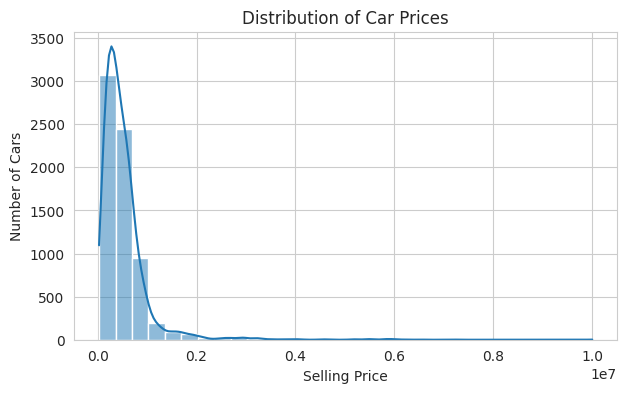

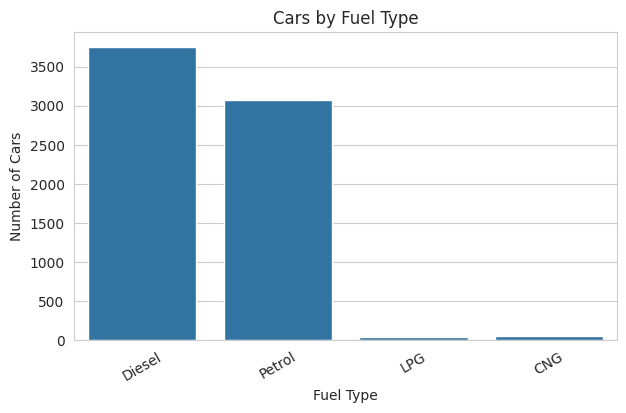

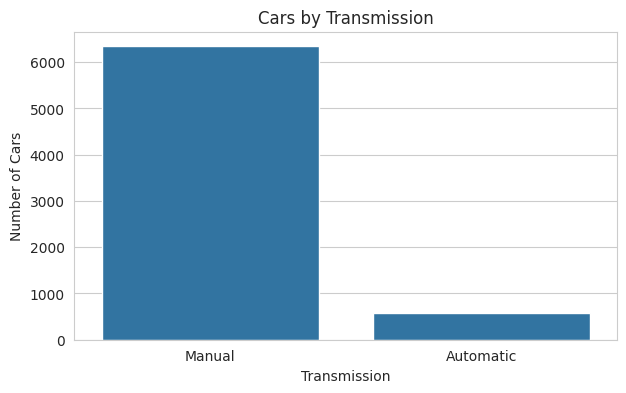

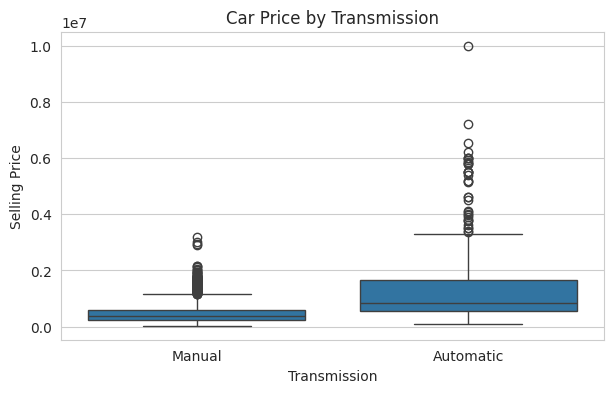

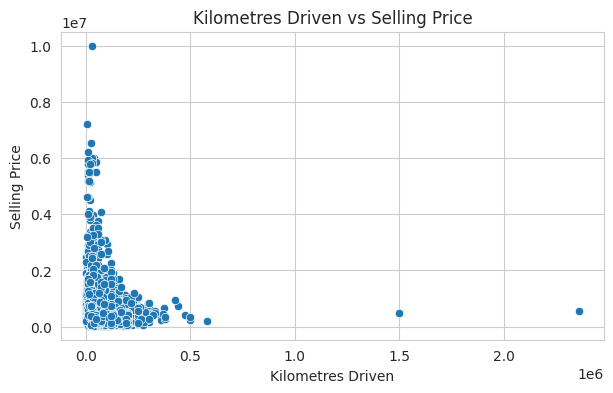

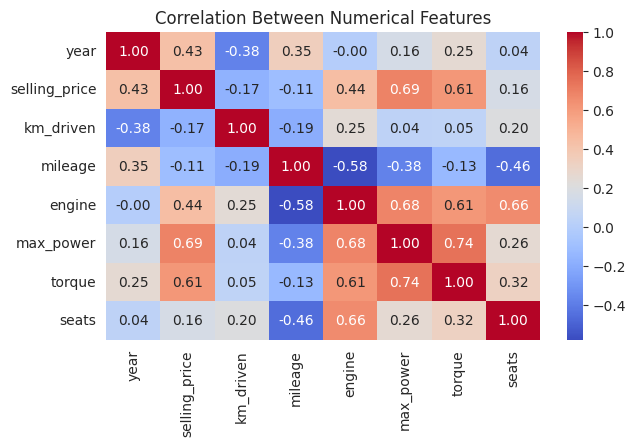

In [17]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# 1. Distribution of car prices
plt.figure(figsize=(7, 4))
sns.histplot(df_clean['selling_price'], bins=30, kde=True)
plt.title("Distribution of Car Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.show()

# 2. Cars by fuel type
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x='fuel')
plt.title("Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.xticks(rotation=30)
plt.show()

# 3. Cars by transmission
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x='transmission')
plt.title("Cars by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Number of Cars")
plt.show()

# 4. Price by transmission
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x='transmission', y='selling_price')
plt.title("Car Price by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")
plt.show()

# 5. Kilometres driven vs selling price
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df_clean, x='km_driven', y='selling_price')
plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")
plt.show()

# 6. Correlation heatmap
plt.figure(figsize=(7, 4))
sns.heatmap(
    df_clean.select_dtypes(include='number').corr(),
    annot=True, cmap='coolwarm', fmt='.2f'
)
plt.title("Correlation Between Numerical Features")
plt.show()


In [18]:

# 1. Most common fuel type
print("Most common fuel type:")
print(df_clean['fuel'].value_counts().head(1))

# 2. Average price by fuel type
print("\nAverage selling price by fuel type:")
print(df_clean.groupby('fuel')['selling_price'].mean().round(2))

# 3. Average price by transmission
print("\nAverage selling price by transmission:")
print(df_clean.groupby('transmission')['selling_price'].mean().round(2))

# 4. Average price by year
print("\nAverage selling price by year:")
print(df_clean.groupby('year')['selling_price'].mean().round(2).tail(10))

# 5. Correlation between kilometres driven and selling price
print("\nCorrelation between kilometres driven and selling price:")
print(round(df_clean['km_driven'].corr(df_clean['selling_price']), 3))

# Additional summary
print("\nFinal dataset shape:", df_clean.shape)


Most common fuel type:
fuel
Diesel    3755
Name: count, dtype: int64

Average selling price by fuel type:
fuel
CNG       300499.95
Diesel    639727.77
LPG       200421.05
Petrol    375688.97
Name: selling_price, dtype: float64

Average selling price by transmission:
transmission
Automatic    1309712.30
Manual        444299.07
Name: selling_price, dtype: float64

Average selling price by year:
year
2011    318335.70
2012    351387.38
2013    451501.72
2014    511858.80
2015    589177.63
2016    653180.34
2017    732419.52
2018    866376.61
2019    949668.55
2020    888349.16
Name: selling_price, dtype: float64

Correlation between kilometres driven and selling price:
-0.166

Final dataset shape: (6926, 13)
